# HW1 — Introduction and Learnability: PAC vs Agnostic PAC

**Statistical and Machine Learning — M2 IM / IMDS / MIAGE — Université de Haute-Alsace**

**Objective.** Experimentally illustrate the difference between the **PAC (realizable)** and the **Agnostic PAC** learning frameworks, using Empirical Risk Minimization (ERM) over the class of threshold classifiers on $\mathcal{X} = [0,1]$.

**Outline**
0. Setup and experimental design (choice of $\theta, \varepsilon, \delta, \eta$, sample sizes, repetitions)
1. Data generation
2. Implementation of ERM
3. Performance evaluation (empirical vs true error)
4. Experimental verification of PAC learning
5. From PAC to Agnostic PAC
6. Conclusion

Only `numpy` (numerical computations), `pandas` (tables) and `matplotlib` (plots) are used. **No machine-learning library is used for the learning algorithm.**

## 0. Setup and experimental design

### Learning problem
- Input space: $\mathcal{X} = [0,1]$, with $\mathcal{D}_X = \mathcal{U}([0,1])$.
- Hypothesis class: $\mathcal{H} = \{ h_t : x \mapsto \mathbb{1}[x > t],\ t \in [0,1] \}$ (VC dimension 1).
- Target: $f_\theta = h_\theta$, so in the realizable setting $f_\theta \in \mathcal{H}$.
- Agnostic setting: each label is flipped independently with probability $\eta$.

### Closed-form true errors (used to validate the test-set estimates)
Because $x \sim \mathcal{U}[0,1]$, the hypothesis $h_t$ disagrees with $f_\theta$ exactly on the interval between $t$ and $\theta$, so:
- **Realizable:** $L_\mathcal{D}(h_t) = |t - \theta|$, and $\min_{h\in\mathcal{H}} L_\mathcal{D}(h) = 0$.
- **Agnostic (noise $\eta$):** $L_\mathcal{D}(h_t) = \eta + (1-2\eta)\,|t-\theta|$, and $\min_{h\in\mathcal{H}} L_\mathcal{D}(h) = \eta$ (Bayes error, reached at $t=\theta$).

### Chosen parameters (and why)
| Parameter | Value | Justification |
|---|---|---|
| $\theta$ | 0.3 | Not centred: classes are unbalanced (70 % of label 1), which is a less trivial case than $\theta=0.5$. |
| $\varepsilon$ | 0.05 | A 5 % excess error is a demanding but reachable accuracy for $m \le 200$ in the realizable case. |
| $\delta$ | 0.05 | Standard 95 % confidence level. |
| $\eta$ | 0.1 (main), plus a sweep over $\{0, 0.05, 0.1, 0.2, 0.3\}$ | 10 % noise is realistic and clearly separates the two regimes. |
| $m$ | $\{5,10,20,50,100,200\}$ (required) + $\{500, 1000, 2000, 5000\}$ (extension) | The extension is needed to see the agnostic regime converge. |
| Repetitions | 1000 | Standard error of an estimated probability $\le \sqrt{0.25/1000} \approx 0.016$. |
| Test set size | 200 000 | Std. error of the test-error estimate $\le \sqrt{0.25/200000} \approx 0.001 \ll \varepsilon$. |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---------------- Experimental parameters ----------------
THETA   = 0.3          # target threshold
EPS     = 0.05         # accuracy parameter epsilon
DELTA   = 0.05         # confidence parameter delta
ETA     = 0.10         # label-noise rate for the agnostic setting
M_LIST  = [5, 10, 20, 50, 100, 200]          # required sample sizes
M_EXT   = M_LIST + [500, 1000, 2000, 5000]   # extended sample sizes
N_REP   = 1000         # repetitions per sample size
N_TEST  = 200_000      # size of the independent test set
SEED    = 42

rng = np.random.default_rng(SEED)

## 1. Data generation

`generate_data(m, theta, eta)` draws $x_1,\dots,x_m \sim \mathcal{U}[0,1]$, computes $y_i = f_\theta(x_i)$ and, if $\eta>0$, flips each label independently with probability $\eta$. With $\eta=0$ we are in the realizable setting.

In [2]:
def target(x, theta=THETA):
    # Target threshold function f_theta(x) = 1 if x > theta else 0
    return (x > theta).astype(int)


def generate_data(m, theta=THETA, eta=0.0, rng=rng):
    # Sample m points uniformly on [0,1], label them with f_theta,
    # then flip each label independently with probability eta.
    x = rng.uniform(0.0, 1.0, size=m)
    y = target(x, theta)
    if eta > 0:
        flip = rng.random(m) < eta
        y = np.where(flip, 1 - y, y)
    return x, y


# One training set per required sample size (realizable setting)
datasets = {m: generate_data(m) for m in M_LIST}
for m, (x, y) in datasets.items():
    print(f"m = {m:4d} | #label 0 = {np.sum(y == 0):3d} | #label 1 = {np.sum(y == 1):3d}")

m =    5 | #label 0 =   1 | #label 1 =   4
m =   10 | #label 0 =   1 | #label 1 =   9
m =   20 | #label 0 =   5 | #label 1 =  15
m =   50 | #label 0 =  17 | #label 1 =  33
m =  100 | #label 0 =  29 | #label 1 =  71
m =  200 | #label 0 =  64 | #label 1 = 136


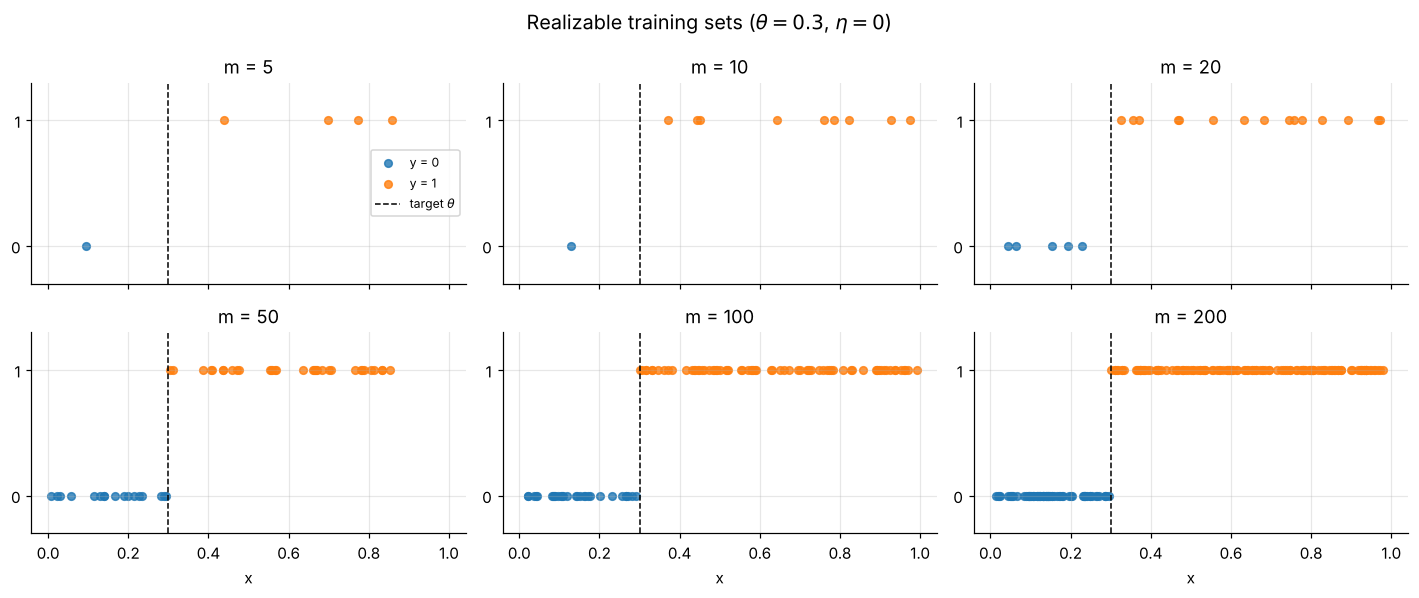

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for ax, m in zip(axes.ravel(), M_LIST):
    x, y = datasets[m]
    ax.scatter(x[y == 0], y[y == 0], c="tab:blue", s=25, label="y = 0", alpha=0.8)
    ax.scatter(x[y == 1], y[y == 1], c="tab:orange", s=25, label="y = 1", alpha=0.8)
    ax.axvline(THETA, color="k", ls="--", lw=1, label=r"target $\theta$")
    ax.set_title(f"m = {m}")
    ax.set_yticks([0, 1]); ax.set_ylim(-0.3, 1.3)
axes[0, 0].legend(loc="center right", fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("x")
fig.suptitle(r"Realizable training sets ($\theta=0.3$, $\eta=0$)", fontsize=13)
plt.tight_layout(); plt.show()

**Interpretation.** In the realizable setting, all points left of $\theta$ have label 0 and all points right of $\theta$ have label 1: the data are perfectly separable by a threshold. With small $m$ (e.g. $m=5$) there may be a large "empty gap" around $\theta$ where the true threshold can lie, which is precisely the source of the generalization error. As $m$ grows, this gap shrinks.

Below, the same comparison with label noise ($\eta = 0.1$): some points now carry the "wrong" label on both sides of $\theta$.

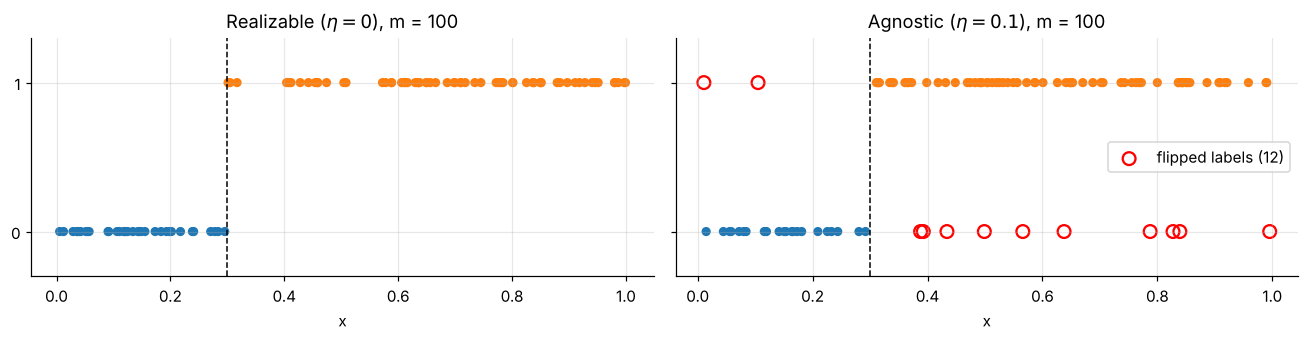

In [4]:
x_c, y_c = generate_data(100, eta=0.0)
x_n, y_n = generate_data(100, eta=ETA)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, (x, y), title in zip(axes, [(x_c, y_c), (x_n, y_n)],
                            ["Realizable ($\\eta=0$)", f"Agnostic ($\\eta={ETA}$)"]):
    wrong = y != target(x)
    ax.scatter(x[~wrong], y[~wrong], c=np.where(y[~wrong] == 1, "tab:orange", "tab:blue"), s=25)
    ax.scatter(x[wrong], y[wrong], facecolors="none", edgecolors="red", s=70, lw=1.5,
               label=f"flipped labels ({wrong.sum()})")
    ax.axvline(THETA, color="k", ls="--", lw=1)
    ax.set_title(f"{title}, m = 100"); ax.set_xlabel("x"); ax.set_yticks([0, 1]); ax.set_ylim(-0.3, 1.3)
    if wrong.any():
        ax.legend(loc="center right")
plt.tight_layout(); plt.show()

## 2. Implementation of ERM

ERM returns $h_S \in \arg\min_{h\in\mathcal{H}} L_S(h)$ with $L_S(h) = \frac{1}{m}\sum_i \mathbb{1}[h(x_i)\ne y_i]$.

### Strategy
Although $\mathcal{H}$ is infinite, $L_S(h_t)$ only changes when $t$ crosses a training point. Sort the points $x_{(1)} \le \dots \le x_{(m)}$; then every threshold $t \in [x_{(k)}, x_{(k+1)})$ produces the **same** labelling (the $k$ leftmost points get label 0, the others label 1). So there are only $m+1$ distinct behaviours, indexed by $k = 0,\dots,m$:

$$ m \cdot L_S(k) = \underbrace{\#\{i \le k : y_{(i)} = 1\}}_{\text{1's predicted 0}} + \underbrace{\#\{i > k : y_{(i)} = 0\}}_{\text{0's predicted 1}} $$

Both counts are obtained for all $k$ at once with **cumulative sums**, so ERM costs $O(m \log m)$ (dominated by sorting), instead of $O(m^2)$ for a naive search.

**Choice of the returned threshold.** Among the minimizing $k$, we return the **midpoint** of the gap $(x_{(k)}, x_{(k+1)})$ (with $x_{(0)} = 0$, $x_{(m+1)} = 1$). Any $t$ in the gap has the same empirical error, but the midpoint is a natural "maximum margin" choice that reduces the true error compared to placing $t$ on a training point. If several $k$ tie (possible in the noisy case), we take the first one.

In [5]:
def erm_threshold(x, y):
    # ERM over threshold classifiers h_t(x) = 1[x > t].
    # Returns (t_hat, empirical_error).
    m = len(x)
    order = np.argsort(x)
    xs, ys = x[order], y[order]

    # ones_left[k]  = number of label-1 points among the k leftmost  (k = 0..m)
    # zeros_right[k] = number of label-0 points among the m-k rightmost
    ones_left   = np.concatenate(([0], np.cumsum(ys)))
    zeros_total = m - ys.sum()
    zeros_left  = np.arange(m + 1) - ones_left
    zeros_right = zeros_total - zeros_left

    errors = ones_left + zeros_right          # misclassifications for each k
    k = int(np.argmin(errors))                # first minimizer

    left  = xs[k - 1] if k > 0 else 0.0       # x_(k)  (or 0)
    right = xs[k]     if k < m else 1.0       # x_(k+1) (or 1)
    t_hat = 0.5 * (left + right)
    return t_hat, errors[k] / m


def predict(t, x):
    return (x > t).astype(int)


def empirical_error(t, x, y):
    return np.mean(predict(t, x) != y)

**Sanity checks.** We check (i) that the fast ERM matches a brute-force search over a fine grid of thresholds, and (ii) that in the realizable case the empirical error is always 0.

In [6]:
def erm_bruteforce(x, y, grid=np.linspace(0, 1, 20001)):
    errs = np.array([empirical_error(t, x, y) for t in grid])
    return grid[np.argmin(errs)], errs.min()

for eta in [0.0, ETA]:
    for m in [5, 20, 100]:
        x, y = generate_data(m, eta=eta)
        t_fast, e_fast = erm_threshold(x, y)
        t_bf, e_bf = erm_bruteforce(x, y)
        assert np.isclose(e_fast, e_bf), (e_fast, e_bf)
        assert np.isclose(empirical_error(t_fast, x, y), e_fast)
        print(f"eta={eta:.2f} m={m:3d} | fast ERM: t={t_fast:.4f}, L_S={e_fast:.3f} | brute force: L_S={e_bf:.3f}")

# realizable: L_S(h_S) must always be 0
assert all(erm_threshold(*generate_data(m))[1] == 0 for m in M_LIST for _ in range(200))
print("\nRealizable case: empirical error of ERM is always 0  ✓")

eta=0.00 m=  5 | fast ERM: t=0.1716, L_S=0.000 | brute force: L_S=0.000
eta=0.00 m= 20 | fast ERM: t=0.3109, L_S=0.000 | brute force: L_S=0.000


eta=0.00 m=100 | fast ERM: t=0.2812, L_S=0.000 | brute force: L_S=0.000
eta=0.10 m=  5 | fast ERM: t=0.3558, L_S=0.000 | brute force: L_S=0.000


eta=0.10 m= 20 | fast ERM: t=0.3455, L_S=0.100 | brute force: L_S=0.100
eta=0.10 m=100 | fast ERM: t=0.3118, L_S=0.060 | brute force: L_S=0.060

Realizable case: empirical error of ERM is always 0  ✓


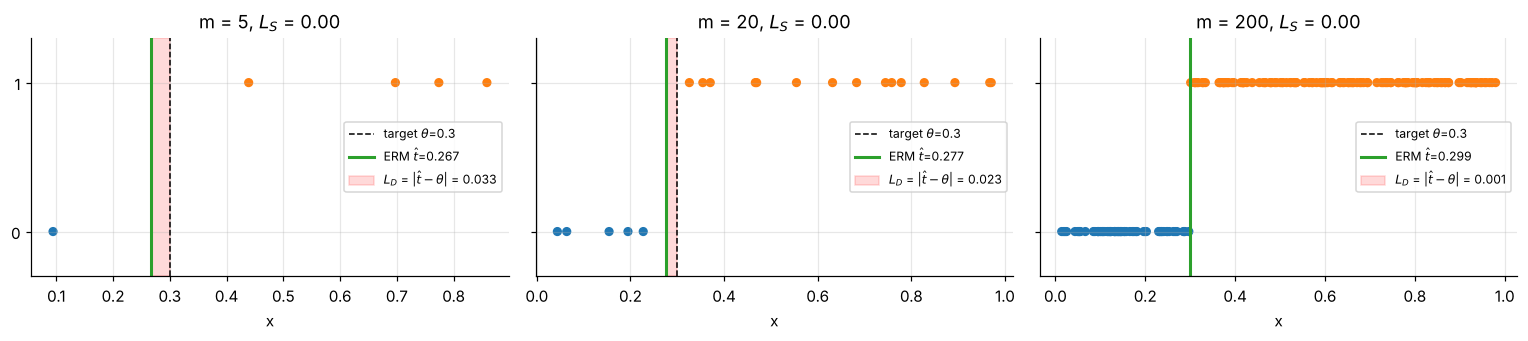

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, m in zip(axes, [5, 20, 200]):
    x, y = datasets[m]
    t_hat, e_hat = erm_threshold(x, y)
    ax.scatter(x, y, c=np.where(y == 1, "tab:orange", "tab:blue"), s=25)
    ax.axvline(THETA, color="k", ls="--", lw=1, label=rf"target $\theta$={THETA}")
    ax.axvline(t_hat, color="tab:green", lw=2, label=rf"ERM $\hat t$={t_hat:.3f}")
    ax.axvspan(min(t_hat, THETA), max(t_hat, THETA), color="red", alpha=0.15,
               label=rf"$L_D$ = |$\hat t-\theta$| = {abs(t_hat-THETA):.3f}")
    ax.set_title(f"m = {m}, $L_S$ = {e_hat:.2f}"); ax.set_xlabel("x")
    ax.set_yticks([0, 1]); ax.set_ylim(-0.3, 1.3); ax.legend(fontsize=8, loc="center right")
plt.tight_layout(); plt.show()

**Interpretation.** The ERM threshold always separates the training data perfectly ($L_S = 0$), but its position is only constrained to lie between the last 0-labelled and first 1-labelled points. The red band is the region where $h_S$ and $f_\theta$ disagree; its width is exactly the true error. It shrinks as $m$ grows.

## 3. Performance evaluation: empirical error vs true error

The true error $L_\mathcal{D}(h_S)$ is estimated on a large independent test set ($N=200\,000$ points drawn from the same distribution, **with the same noise level** as the training data). To evaluate thousands of hypotheses quickly, the test set is sorted once; the number of errors of $h_t$ is then obtained with a binary search (`np.searchsorted`) and cumulative sums, in $O(\log N)$ per hypothesis.

We also compare with the closed-form value $L_\mathcal{D}(h_t) = \eta + (1-2\eta)|t-\theta|$ to validate the estimates.

In [8]:
class TestSet:
    # Large independent test set allowing O(log N) evaluation of any threshold.
    def __init__(self, n, eta, rng=rng):
        x, y = generate_data(n, eta=eta, rng=rng)
        order = np.argsort(x)
        self.x, self.y, self.n = x[order], y[order], n
        self.ones_left = np.concatenate(([0], np.cumsum(self.y)))
        self.zeros_total = n - self.y.sum()

    def error(self, t):
        # Test error of h_t (t can be a scalar or an array).
        k = np.searchsorted(self.x, t, side="right")          # points <= t are predicted 0
        ones_left = self.ones_left[k]
        zeros_right = self.zeros_total - (k - ones_left)
        return (ones_left + zeros_right) / self.n


def true_error_closed_form(t, theta=THETA, eta=0.0):
    return eta + (1 - 2 * eta) * np.abs(np.asarray(t) - theta)


test_clean = TestSet(N_TEST, eta=0.0)
test_noisy = TestSet(N_TEST, eta=ETA)

# Validation of the test-set estimate against the closed form
ts = np.array([0.0, 0.1, 0.25, 0.3, 0.35, 0.6, 1.0])
print(pd.DataFrame({
    "t": ts,
    "test err (eta=0)": test_clean.error(ts).round(4),
    "closed form (eta=0)": true_error_closed_form(ts).round(4),
    f"test err (eta={ETA})": test_noisy.error(ts).round(4),
    f"closed form (eta={ETA})": true_error_closed_form(ts, eta=ETA).round(4),
}).to_string(index=False))

   t  test err (eta=0)  closed form (eta=0)  test err (eta=0.1)  closed form (eta=0.1)
0.00            0.3011                 0.30              0.3408                   0.34
0.10            0.2015                 0.20              0.2600                   0.26
0.25            0.0498                 0.05              0.1392                   0.14
0.30            0.0000                 0.00              0.0991                   0.10
0.35            0.0495                 0.05              0.1394                   0.14
0.60            0.2993                 0.30              0.3403                   0.34
1.00            0.6989                 0.70              0.6592                   0.66


The test-set estimates agree with the closed form up to $\approx 10^{-3}$, so the test set is large enough. We now compute, for each training set, the empirical error $L_S(h_S)$ and the true error $L_\mathcal{D}(h_S)$, in both settings.

In [9]:
rows = []
for eta, test in [(0.0, test_clean), (ETA, test_noisy)]:
    for m in M_LIST:
        x, y = generate_data(m, eta=eta)
        t_hat, emp = erm_threshold(x, y)
        rows.append({"setting": "realizable" if eta == 0 else f"agnostic (eta={eta})",
                     "m": m, "t_hat": round(t_hat, 4), "empirical error L_S": round(emp, 4),
                     "true error L_D (test set)": round(float(test.error(t_hat)), 4),
                     "gap L_D - L_S": round(float(test.error(t_hat)) - emp, 4)})
table_single = pd.DataFrame(rows)
table_single

,setting,m,t_hat,empirical error L_S,true error L_D (test set),gap L_D - L_S
0,realizable,5,0.2594,0.000,0.0406,0.0406
1,realizable,10,0.2979,0.000,0.0022,0.0022
2,realizable,20,0.2698,0.000,0.0302,0.0302
3,realizable,50,0.2856,0.000,0.0144,0.0144
4,realizable,100,0.2998,0.000,0.0002,0.0002
5,realizable,200,0.2999,0.000,0.0001,0.0001
6,agnostic (eta=0.1),5,0.4520,0.000,0.2216,0.2216
7,agnostic (eta=0.1),10,0.3250,0.200,0.1192,-0.0808
8,agnostic (eta=0.1),20,0.3317,0.150,0.1248,-0.0252
9,agnostic (eta=0.1),50,0.2799,0.120,0.1152,-0.0048


A single training set is noisy, so we average over the $N_{rep}=1000$ repetitions. The function below is reused in Sections 4 and 5: for each $m$ it runs ERM on 1000 independent training sets and stores $\hat t$, $L_S(h_S)$ and $L_\mathcal{D}(h_S)$.

In [10]:
def run_experiment(m_list, eta, test, n_rep=N_REP, rng=rng):
    # For each m: n_rep independent training sets -> ERM -> (t_hat, L_S, L_D).
    res = {}
    for m in m_list:
        t_hats, emp = np.empty(n_rep), np.empty(n_rep)
        for r in range(n_rep):
            x, y = generate_data(m, eta=eta, rng=rng)
            t_hats[r], emp[r] = erm_threshold(x, y)
        res[m] = {"t_hat": t_hats, "L_S": emp,
                  "L_D": test.error(t_hats),                              # test-set estimate
                  "L_D_exact": true_error_closed_form(t_hats, eta=eta)}   # closed form
    return res


res_real  = run_experiment(M_EXT, 0.0, test_clean)
# NB: the test-set estimate has a resolution of ~1e-3 (its own realised noise rate is not exactly eta),
# so the *excess risk* L_D - eta, which becomes smaller than 1e-3 for large m, is computed with the
# closed form. The test-set estimate is used for L_D itself.
res_agnos = run_experiment(M_EXT, ETA, test_noisy)

def summary(res, eta):
    return pd.DataFrame([{"m": m,
                          "mean L_S": r["L_S"].mean(), "mean L_D": r["L_D"].mean(),
                          "mean gap": (r["L_D"] - r["L_S"]).mean(),
                          "mean excess risk (exact)": r["L_D_exact"].mean() - eta}
                         for m, r in res.items()]).round(4)

print("Realizable setting (eta = 0)"); display(summary(res_real, 0.0))
print(f"Agnostic setting (eta = {ETA})"); display(summary(res_agnos, ETA))

Realizable setting (eta = 0)


,m,mean L_S,mean L_D,mean gap,mean excess risk (exact)
0,5,0.0,0.0743,0.0743,0.0744
1,10,0.0,0.0458,0.0458,0.0459
2,20,0.0,0.0234,0.0234,0.0235
3,50,0.0,0.0099,0.0099,0.0099
4,100,0.0,0.0052,0.0052,0.0051
5,200,0.0,0.0025,0.0025,0.0024
6,500,0.0,0.0011,0.0011,0.0011
7,1000,0.0,0.0005,0.0005,0.0005
8,2000,0.0,0.0003,0.0003,0.0003
9,5000,0.0,0.0001,0.0001,0.0001


Agnostic setting (eta = 0.1)


,m,mean L_S,mean L_D,mean gap,mean excess risk (exact)
0,5,0.0624,0.1899,0.1275,0.0903
1,10,0.0810,0.1629,0.0819,0.0635
2,20,0.0906,0.1360,0.0454,0.0367
3,50,0.0956,0.1154,0.0198,0.0162
4,100,0.0984,0.1073,0.0089,0.0081
5,200,0.0985,0.1031,0.0046,0.0040
6,500,0.0992,0.1008,0.0016,0.0017
7,1000,0.0993,0.0999,0.0007,0.0008
8,2000,0.0997,0.0995,-0.0002,0.0004
9,5000,0.1000,0.0993,-0.0007,0.0002


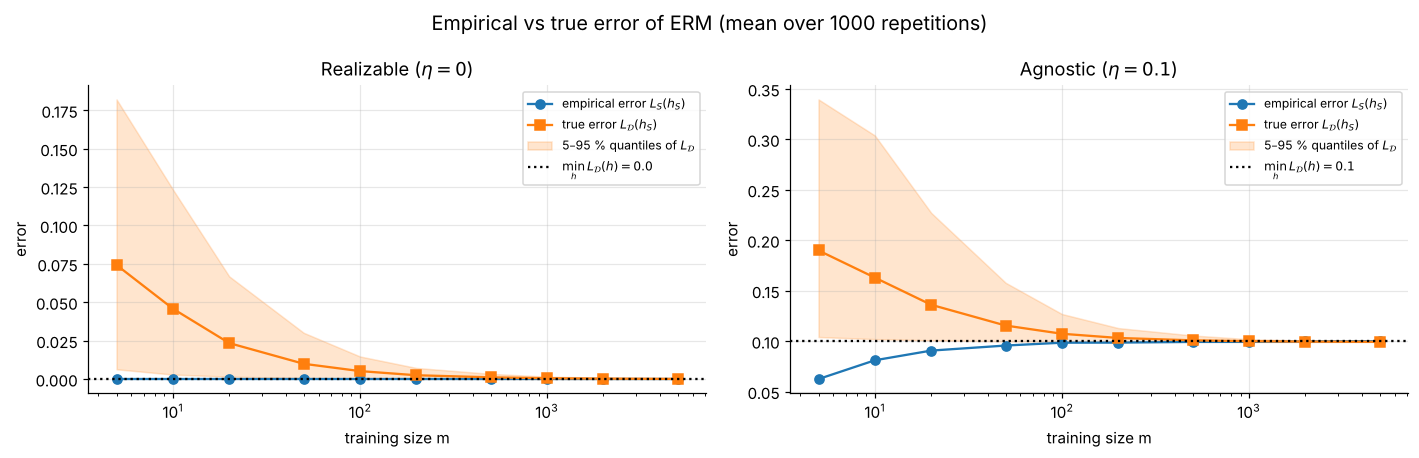

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, res, eta, title in [(axes[0], res_real, 0.0, "Realizable ($\\eta=0$)"),
                           (axes[1], res_agnos, ETA, f"Agnostic ($\\eta={ETA}$)")]:
    ms = np.array(list(res))
    ls = np.array([res[m]["L_S"].mean() for m in ms])
    ld = np.array([res[m]["L_D"].mean() for m in ms])
    ld_q = np.array([np.quantile(res[m]["L_D"], [0.05, 0.95]) for m in ms])
    ax.plot(ms, ls, "o-", label=r"empirical error $L_S(h_S)$")
    ax.plot(ms, ld, "s-", label=r"true error $L_\mathcal{D}(h_S)$")
    ax.fill_between(ms, ld_q[:, 0], ld_q[:, 1], alpha=0.2, color="tab:orange",
                    label=r"5–95 % quantiles of $L_\mathcal{D}$")
    ax.axhline(eta, color="k", ls=":", label=rf"$\min_h L_\mathcal{{D}}(h) = {eta}$")
    ax.set_xscale("log"); ax.set_xlabel("training size m"); ax.set_ylabel("error")
    ax.set_title(title); ax.legend(fontsize=8)
plt.suptitle(f"Empirical vs true error of ERM (mean over {N_REP} repetitions)", fontsize=13)
plt.tight_layout(); plt.show()

**Interpretation.**
- **Realizable:** $L_S(h_S) = 0$ for every training set — ERM always finds a consistent hypothesis since $f_\theta \in \mathcal{H}$. The true error is positive but decreases quickly, roughly like $1/m$ (for thresholds, $\mathbb{E}[L_\mathcal{D}(h_S)] \approx \frac{1}{2(m+1)}$ with the midpoint rule). The gap $L_\mathcal{D}-L_S$ equals $L_\mathcal{D}$ itself.
- **Agnostic:** $L_S(h_S)$ is now strictly positive and is **optimistic**: for small $m$ it is well **below** $\eta$ because ERM overfits the noise (it picks the threshold that happens to fit the noisy sample best). As $m$ increases, $L_S$ increases towards $\eta$ while $L_\mathcal{D}$ decreases towards $\eta$: the two curves meet at the Bayes error $\eta = 0.1$, never at 0. The convergence is visibly slower than in the realizable case.

## 4. Experimental verification of PAC learning (realizable setting)

**PAC definition.** $\mathcal{H}$ is PAC learnable if there is $m_\mathcal{H}(\varepsilon,\delta)$ such that for $m \ge m_\mathcal{H}(\varepsilon,\delta)$, with probability at least $1-\delta$ over $S \sim \mathcal{D}^m$: $L_\mathcal{D}(h_S) \le \varepsilon$.

We therefore estimate, for each $m$, the probability of failure
$$\widehat{P}_m = \frac{1}{N_{rep}}\sum_{r=1}^{N_{rep}} \mathbb{1}\big[L_\mathcal{D}(h_S^{(r)}) > \varepsilon\big].$$

**Theoretical bounds for comparison.**
- *Exact analysis for thresholds:* ERM fails only if no training point falls in $(\theta-\varepsilon', \theta)$ or $(\theta, \theta+\varepsilon')$ for a suitable $\varepsilon'$. With the midpoint rule, failure requires a gap of width $>2\varepsilon$ around $\theta$; a simple union bound gives $\Pr(L_\mathcal{D}(h_S) > \varepsilon) \le 2(1-\varepsilon)^m \le 2e^{-\varepsilon m}$, i.e. it suffices to have
$$ m \ge \frac{\ln(2/\delta)}{\varepsilon}. $$
- *Generic VC bound (realizable), $d=1$:* $m_\mathcal{H}(\varepsilon,\delta) = O\!\left(\frac{d\ln(1/\varepsilon) + \ln(1/\delta)}{\varepsilon}\right)$ — the key point is the $1/\varepsilon$ dependence.

In [12]:
def failure_prob(res, eps, eta=0.0):
    # Fraction of repetitions with excess risk L_D(h_S) - min L_D > eps (min L_D = eta).
    ms = np.array(list(res))
    p = np.array([np.mean(res[m]["L_D_exact"] - eta > eps) for m in ms])
    se = np.sqrt(p * (1 - p) / N_REP)
    return ms, p, se

ms, p_real, se_real = failure_prob(res_real, EPS)
bound = np.minimum(1, 2 * (1 - EPS) ** ms)
m_needed = int(np.ceil(np.log(2 / DELTA) / EPS))

display(pd.DataFrame({"m": ms, "P(L_D > eps) estimated": p_real.round(4),
                      "std. error": se_real.round(4), "bound 2(1-eps)^m": bound.round(4),
                      "PAC guarantee (P <= delta) ?": np.where(p_real <= DELTA, "yes", "no")}))
print(f"Theoretical sufficient sample size  m >= ln(2/delta)/eps = {m_needed}")

,m,P(L_D > eps) estimated,std. error,bound 2(1-eps)^m,PAC guarantee (P <= delta) ?
0,5,0.577,0.0156,1.0000,no
1,10,0.362,0.0152,1.0000,no
2,20,0.124,0.0104,0.7170,no
3,50,0.008,0.0028,0.1539,yes
4,100,0.000,0.0000,0.0118,yes
5,200,0.000,0.0000,0.0001,yes
6,500,0.000,0.0000,0.0000,yes
7,1000,0.000,0.0000,0.0000,yes
8,2000,0.000,0.0000,0.0000,yes
9,5000,0.000,0.0000,0.0000,yes


Theoretical sufficient sample size  m >= ln(2/delta)/eps = 74


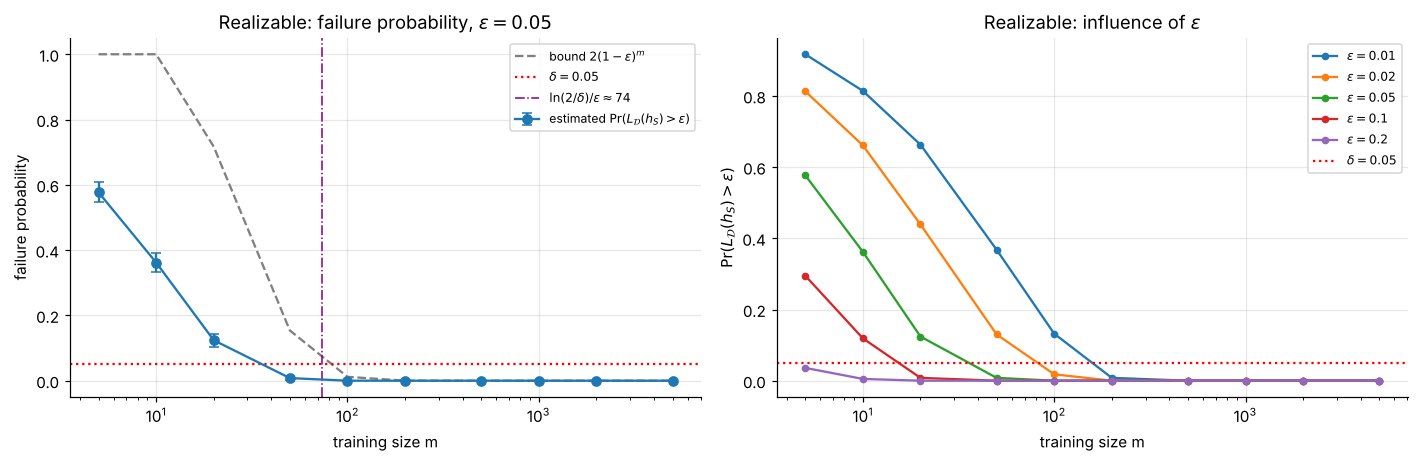

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

ax = axes[0]
ax.errorbar(ms, p_real, yerr=1.96 * se_real, fmt="o-", capsize=3, label=r"estimated $\Pr(L_\mathcal{D}(h_S) > \varepsilon)$")
ax.plot(ms, bound, "--", color="gray", label=r"bound $2(1-\varepsilon)^m$")
ax.axhline(DELTA, color="red", ls=":", label=rf"$\delta = {DELTA}$")
ax.axvline(m_needed, color="purple", ls="-.", lw=1, label=rf"$\ln(2/\delta)/\varepsilon \approx {m_needed}$")
ax.set_xscale("log"); ax.set_xlabel("training size m"); ax.set_ylabel("failure probability")
ax.set_title(rf"Realizable: failure probability, $\varepsilon={EPS}$"); ax.legend(fontsize=8)

ax = axes[1]
for eps in [0.01, 0.02, 0.05, 0.1, 0.2]:
    m_, p_, _ = failure_prob(res_real, eps)
    ax.plot(m_, p_, "o-", ms=4, label=rf"$\varepsilon={eps}$")
ax.axhline(DELTA, color="red", ls=":", label=rf"$\delta={DELTA}$")
ax.set_xscale("log"); ax.set_xlabel("training size m"); ax.set_ylabel(r"$\Pr(L_\mathcal{D}(h_S) > \varepsilon)$")
ax.set_title("Realizable: influence of $\\varepsilon$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

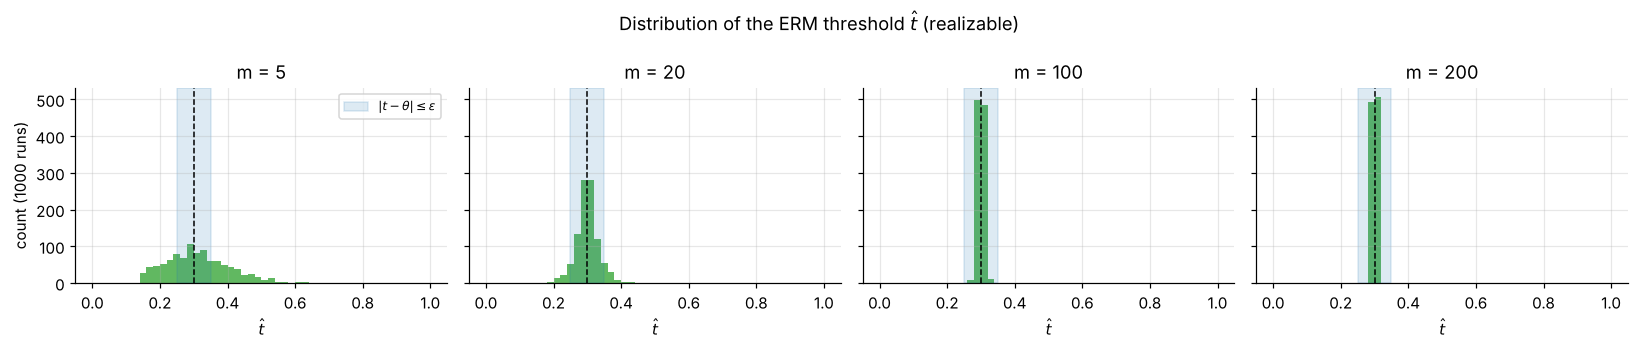

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, m in zip(axes, [5, 20, 100, 200]):
    ax.hist(res_real[m]["t_hat"], bins=50, range=(0, 1), color="tab:green", alpha=0.75)
    ax.axvspan(THETA - EPS, THETA + EPS, color="tab:blue", alpha=0.15, label=r"$|t-\theta|\leq\varepsilon$")
    ax.axvline(THETA, color="k", ls="--", lw=1)
    ax.set_title(f"m = {m}"); ax.set_xlabel(r"$\hat t$")
axes[0].set_ylabel("count (1000 runs)"); axes[0].legend(fontsize=8)
fig.suptitle(r"Distribution of the ERM threshold $\hat t$ (realizable)", fontsize=12)
plt.tight_layout(); plt.show()

**Interpretation.**
- The failure probability $\Pr(L_\mathcal{D}(h_S) > \varepsilon)$ decreases **exponentially fast** with $m$ (0.57 at $m=5$, 0.12 at $m=20$, 0.008 at $m=50$, 0 from $m=100$), and always stays below the theoretical bound $2(1-\varepsilon)^m$, which is therefore valid but conservative.
- With $\varepsilon = 0.05$ and $\delta=0.05$, the empirical failure probability falls below $\delta$ already at $m = 50$, consistent with (and smaller than) the sufficient size $\ln(2/\delta)/\varepsilon \approx 74$.
- The histograms show the ERM threshold concentrating around $\theta$: its spread scales like $1/m$.
- Smaller $\varepsilon$ requires proportionally more data ($m \propto 1/\varepsilon$): the curves on the right are shifted to the right roughly by the ratio of the $\varepsilon$'s.

This is exactly the **PAC guarantee**: for every $(\varepsilon,\delta)$ there is a finite $m$ beyond which ERM is *probably* ($1-\delta$) *approximately* ($\varepsilon$) *correct*.

## 5. From PAC to Agnostic PAC

With label noise, no hypothesis is perfect: $\min_{h\in\mathcal{H}} L_\mathcal{D}(h) = \eta > 0$. Requiring $L_\mathcal{D}(h_S)\le\varepsilon$ is then **impossible** as soon as $\varepsilon < \eta$. The Agnostic PAC criterion instead compares to the best hypothesis in the class:
$$\Pr\Big(L_\mathcal{D}(h_S) > \min_{h\in\mathcal{H}} L_\mathcal{D}(h) + \varepsilon\Big) \le \delta .$$

We estimate both quantities:
1. the **PAC criterion** $\Pr(L_\mathcal{D}(h_S) > \varepsilon)$ (as in Section 4),
2. the **Agnostic PAC criterion** $\Pr(L_\mathcal{D}(h_S) - \eta > \varepsilon)$.

**Theoretical sample complexity (agnostic, uniform convergence).** For a class of VC dimension $d$, $m_\mathcal{H}(\varepsilon,\delta) = O\!\left(\frac{d + \ln(1/\delta)}{\varepsilon^2}\right)$ — a $1/\varepsilon^2$ dependence instead of $1/\varepsilon$. Note also that since $L_\mathcal{D}(h_t) - \eta = (1-2\eta)|t-\theta|$, the excess risk is $\le\varepsilon$ iff $|\hat t-\theta| \le \varepsilon/(1-2\eta)$.

In [15]:
ms_a, p_agn, se_agn = failure_prob(res_agnos, EPS, eta=ETA)       # agnostic criterion
_,    p_pac_on_noisy, _ = failure_prob(res_agnos, EPS, eta=0.0)   # PAC criterion on noisy data

comp = pd.DataFrame({
    "m": ms_a,
    "realizable: P(L_D > eps)": p_real.round(3),
    "agnostic: P(L_D > eps)  [PAC criterion]": p_pac_on_noisy.round(3),
    "agnostic: P(L_D > eta + eps)  [agnostic criterion]": p_agn.round(3),
    "realizable: P(L_S = 0)": [np.mean(res_real[m]["L_S"] == 0) for m in ms_a],
    "agnostic: P(L_S = 0)": [np.mean(res_agnos[m]["L_S"] == 0) for m in ms_a],
})
comp

,m,realizable: P(L_D > eps),agnostic: P(L_D > eps) [PAC criterion],agnostic: P(L_D > eta + eps) [agnostic criterion],realizable: P(L_S = 0),agnostic: P(L_S = 0)
0,5,0.577,1.0,0.608,1.0,0.715
1,10,0.362,1.0,0.436,1.0,0.406
2,20,0.124,1.0,0.228,1.0,0.128
3,50,0.008,1.0,0.071,1.0,0.004
4,100,0.000,1.0,0.013,1.0,0.000
5,200,0.000,1.0,0.000,1.0,0.000
6,500,0.000,1.0,0.000,1.0,0.000
7,1000,0.000,1.0,0.000,1.0,0.000
8,2000,0.000,1.0,0.000,1.0,0.000
9,5000,0.000,1.0,0.000,1.0,0.000


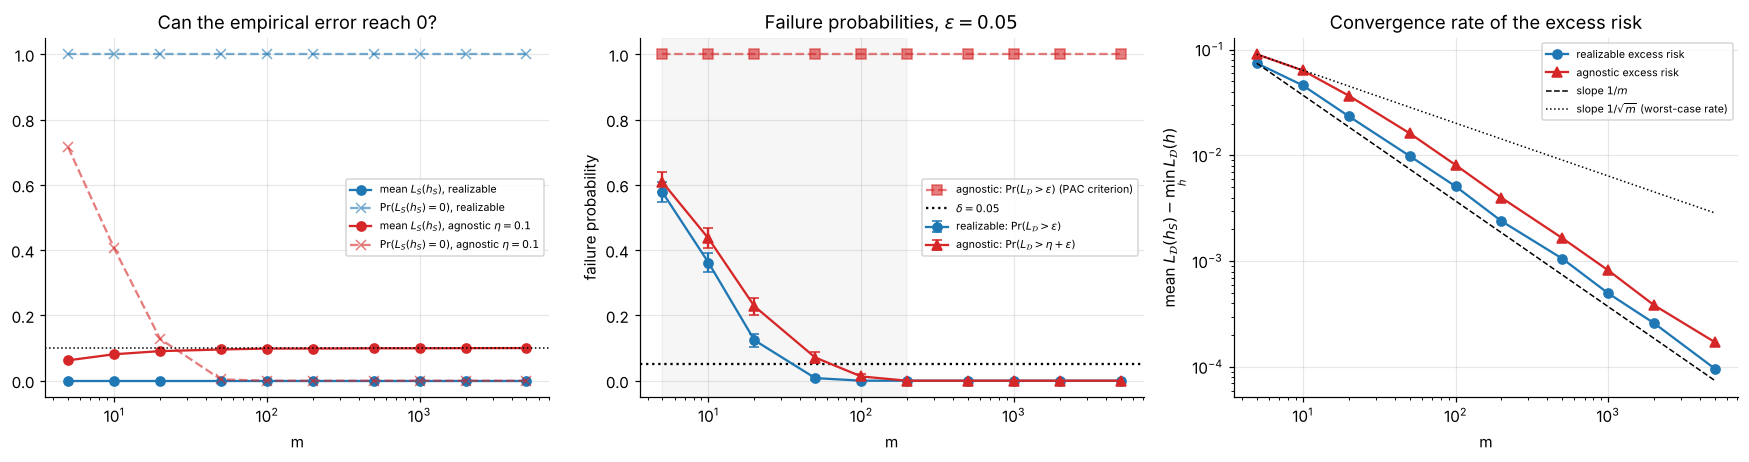

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

# (a) empirical error distribution
ax = axes[0]
for res, lab, c in [(res_real, "realizable", "tab:blue"), (res_agnos, f"agnostic $\\eta={ETA}$", "tab:red")]:
    m_ = np.array(list(res))
    mean = np.array([res[m]["L_S"].mean() for m in m_])
    p0 = np.array([np.mean(res[m]["L_S"] == 0) for m in m_])
    ax.plot(m_, mean, "o-", color=c, label=rf"mean $L_S(h_S)$, {lab}")
    ax.plot(m_, p0, "x--", color=c, alpha=0.6, label=rf"$\Pr(L_S(h_S)=0)$, {lab}")
ax.axhline(ETA, color="k", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_title("Can the empirical error reach 0?"); ax.legend(fontsize=7)

# (b) failure probabilities
ax = axes[1]
ax.errorbar(ms, p_real, yerr=1.96 * se_real, fmt="o-", capsize=3, color="tab:blue",
            label=r"realizable: $\Pr(L_\mathcal{D} > \varepsilon)$")
ax.plot(ms_a, p_pac_on_noisy, "s--", color="tab:red", alpha=0.6,
        label=r"agnostic: $\Pr(L_\mathcal{D} > \varepsilon)$ (PAC criterion)")
ax.errorbar(ms_a, p_agn, yerr=1.96 * se_agn, fmt="^-", capsize=3, color="tab:red",
            label=r"agnostic: $\Pr(L_\mathcal{D} > \eta + \varepsilon)$")
ax.axhline(DELTA, color="k", ls=":", label=rf"$\delta={DELTA}$")
ax.axvspan(min(M_LIST), max(M_LIST), color="gray", alpha=0.07)
ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_ylabel("failure probability")
ax.set_title(rf"Failure probabilities, $\varepsilon={EPS}$"); ax.legend(fontsize=7)

# (c) excess risk decay rates
ax = axes[2]
ex_r = np.array([res_real[m]["L_D_exact"].mean() for m in ms])
ex_a = np.array([res_agnos[m]["L_D_exact"].mean() - ETA for m in ms_a])
ax.loglog(ms, ex_r, "o-", color="tab:blue", label="realizable excess risk")
ax.loglog(ms_a, ex_a, "^-", color="tab:red", label="agnostic excess risk")
ax.loglog(ms, ex_r[0] * ms[0] / ms, "k--", lw=1, label=r"slope $1/m$")
ax.loglog(ms_a, ex_a[0] * np.sqrt(ms_a[0] / ms_a), "k:", lw=1, label=r"slope $1/\sqrt{m}$ (worst-case rate)")
ax.set_xlabel("m"); ax.set_ylabel(r"mean $L_\mathcal{D}(h_S) - \min_h L_\mathcal{D}(h)$")
ax.set_title("Convergence rate of the excess risk"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Interpretation.**
- **Panel (a):** in the realizable case $L_S(h_S)=0$ with probability 1. With noise, $\Pr(L_S(h_S)=0)$ is non-zero only for tiny samples (when by chance no flipped label conflicts with a threshold) and vanishes quickly; the mean empirical error converges to $\eta$, not to 0.
- **Panel (b):** under noise, the *PAC* criterion $\Pr(L_\mathcal{D}(h_S) > \varepsilon)$ stays equal to **1 for every $m$**, because $L_\mathcal{D}(h) \ge \eta = 0.1 > \varepsilon$ for every $h$: no amount of data can satisfy it. The *agnostic* criterion, on the other hand, does go to 0 — but more slowly than in the realizable case: with $\varepsilon=\delta=0.05$ it needs $m=100$ (failure 0.013) instead of $m=50$, and at $m=50$ it is still 0.071 vs 0.008 (shaded area = required sizes $m\le 200$).
- **Panel (c):** the excess risk goes to 0 in both settings, but the agnostic curve sits clearly above the realizable one (about 1.2–1.6× higher, e.g. 0.0081 vs 0.0051 at $m=100$): the noise costs extra samples. Interestingly, the observed slope is close to $1/m$ in both cases, much better than the worst-case $1/\sqrt{m}$ rate of the agnostic theory. This is because our noise is "benign" (constant $\eta<1/2$, so-called Massart noise): the label distribution changes sharply at $\theta$, which allows fast rates. The $O(1/\varepsilon^2)$ agnostic sample complexity is a *worst case over all distributions*; it is an upper bound, and particular distributions can be easier.

### 5.1 Influence of the noise rate $\eta$

To see how the difficulty evolves continuously, we repeat the agnostic experiment for $\eta \in \{0, 0.05, 0.1, 0.2, 0.3\}$ (500 repetitions each, to keep runtime reasonable).

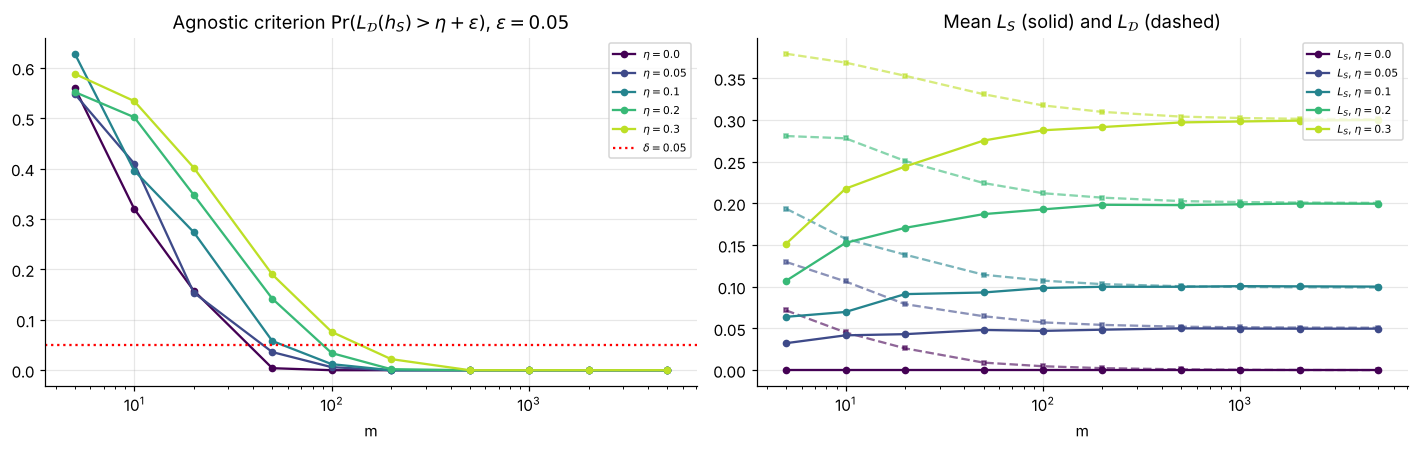

,eta,smallest tested m with P(excess > eps) <= delta
0,0.00,50
1,0.05,50
2,0.10,100
3,0.20,100
4,0.30,200


In [17]:
ETAS = [0.0, 0.05, 0.10, 0.20, 0.30]
res_eta = {}
for eta in ETAS:
    test = TestSet(N_TEST, eta=eta)
    res_eta[eta] = run_experiment(M_EXT, eta, test, n_rep=500)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(ETAS)))
for c, eta in zip(cmap, ETAS):
    r = res_eta[eta]; m_ = np.array(list(r))
    axes[0].plot(m_, [np.mean(r[m]["L_D_exact"] - eta > EPS) for m in m_], "o-", ms=4, color=c, label=rf"$\eta={eta}$")
    axes[1].plot(m_, [r[m]["L_S"].mean() for m in m_], "o-", ms=4, color=c, label=rf"$L_S$, $\eta={eta}$")
    axes[1].plot(m_, [r[m]["L_D"].mean() for m in m_], "s--", ms=3, color=c, alpha=0.6)
axes[0].axhline(DELTA, color="red", ls=":", label=rf"$\delta={DELTA}$")
axes[0].set_title(rf"Agnostic criterion $\Pr(L_\mathcal{{D}}(h_S) > \eta+\varepsilon)$, $\varepsilon={EPS}$")
axes[1].set_title(r"Mean $L_S$ (solid) and $L_\mathcal{D}$ (dashed)")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("m"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

def first_m_below(r, eta, eps=EPS, delta=DELTA):
    for m in r:
        if np.mean(r[m]["L_D_exact"] - eta > eps) <= delta:
            return m
    return f"> {max(r)}"

display(pd.DataFrame({"eta": ETAS,
                      "smallest tested m with P(excess > eps) <= delta": [first_m_below(res_eta[e], e) for e in ETAS]}))

**Interpretation.** The more noise, the more examples are needed to reach the same $(\varepsilon,\delta)$ guarantee: each noisy label pushes ERM towards a wrong threshold, and the "signal" separating good from bad thresholds is weaker (the excess risk is $(1-2\eta)|t-\theta|$, the label distribution near $\theta$ is less contrasted). On the right, the gap between $L_\mathcal{D}$ (dashed) and $L_S$ (solid) is larger for larger $\eta$ at small $m$: ERM overfits the noise. In every case both curves converge to the Bayes error $\eta$, never to 0 (unless $\eta=0$).

### 5.2 Answers to the questions

**Can the empirical error still reach zero?**
In the realizable case, always ($L_S(h_S)=0$ for every sample, since $f_\theta\in\mathcal{H}$). In the agnostic case, essentially **no**: it can happen for very small $m$ by chance (no flipped label creates a conflict), but this probability decays exponentially with $m$, and $L_S(h_S)\to\eta>0$. Moreover, a small $L_S$ is misleading: for small $m$, $L_S(h_S) < \eta \le L_\mathcal{D}(h_S)$, which is a sign of overfitting the noise.

**Does increasing the number of training examples still improve generalization?**
**Yes, but towards a different target and more slowly.** $L_\mathcal{D}(h_S)$ decreases with $m$ and converges to $\min_h L_\mathcal{D}(h) = \eta$, not to 0. The excess risk $L_\mathcal{D}(h_S) - \eta$ goes to 0 and $\Pr(L_\mathcal{D}(h_S) > \eta+\varepsilon)\to 0$, but more examples are needed than in the realizable case (here 100 instead of 50 for $\eta=0.1$, 200 for $\eta=0.3$). What **cannot** be improved is the irreducible error $\eta$: $\Pr(L_\mathcal{D}(h_S) > \varepsilon)=1$ for all $m$ when $\varepsilon<\eta$.

**Relation to the PAC and Agnostic PAC frameworks.**
- *PAC (realizable):* the assumption $\exists h^\star\in\mathcal{H},\ L_\mathcal{D}(h^\star)=0$ holds, ERM returns a consistent hypothesis and we verified $\Pr(L_\mathcal{D}(h_S)>\varepsilon)\le\delta$ for $m$ of the order of $\ln(1/\delta)/\varepsilon$, matching the $O(\frac{d\ln(1/\varepsilon)+\ln(1/\delta)}{\varepsilon})$ sample complexity.
- *Agnostic PAC:* the realizability assumption fails, so the PAC requirement is unattainable. The class is still agnostic PAC learnable (finite VC dimension $\Rightarrow$ uniform convergence $\Rightarrow$ ERM works): we observed $\Pr(L_\mathcal{D}(h_S) > \min_h L_\mathcal{D}(h)+\varepsilon)\to 0$, with a larger sample requirement. The theory gives the worst-case bound $O(\frac{d+\ln(1/\delta)}{\varepsilon^2})$; our benign constant noise is easier than this worst case, and the observed sizes are well within the bound. ERM is no longer guaranteed to have $L_S=0$; it is justified by the fact that $L_S(h)$ is uniformly close to $L_\mathcal{D}(h)$ for all $h\in\mathcal{H}$ when $m$ is large ($\varepsilon/2$-representative sample).

## 6. Conclusion

| | **PAC (realizable, $\eta=0$)** | **Agnostic PAC ($\eta>0$)** |
|---|---|---|
| Best achievable error in $\mathcal{H}$ | $0$ | $\eta$ (Bayes error) |
| Empirical error of ERM | always $0$ | $>0$, tends to $\eta$; underestimates $L_\mathcal{D}$ for small $m$ |
| Guarantee | $L_\mathcal{D}(h_S)\le\varepsilon$ w.p. $\ge1-\delta$ | $L_\mathcal{D}(h_S)\le\min_h L_\mathcal{D}(h)+\varepsilon$ w.p. $\ge1-\delta$ |
| Does more data help? | yes, $L_\mathcal{D}\to0$ fast (≈ $1/m$) | yes, but only the excess risk $\to0$ (with a larger constant); $L_\mathcal{D}\to\eta$ |
| Sample complexity (theory) | $O\big(\frac{d\ln(1/\varepsilon)+\ln(1/\delta)}{\varepsilon}\big)$ | $O\big(\frac{d+\ln(1/\delta)}{\varepsilon^2}\big)$ (worst case) |
| Observed, $\varepsilon=\delta=0.05$ | $m = 50$ suffices | $m=100$ for $\eta=0.1$, $m=200$ for $\eta=0.3$ |

**Take-away.** Our experiments show that ERM over thresholds is a PAC learner when the data are realizable: the failure probability $\Pr(L_\mathcal{D}(h_S)>\varepsilon)$ decreases exponentially and drops below $\delta$ with a few dozen examples. As soon as labels are noisy, the same criterion becomes impossible to satisfy ($=1$ for every $m$) because no threshold has error below $\eta$. The meaningful goal becomes the agnostic one — competing with the best hypothesis in the class — and ERM still achieves it, but needs more data, and more so as the noise level increases. For this simple class with constant noise the slowdown we observe is moderate (a constant factor), smaller than the worst-case $1/\varepsilon^2$ theory predicts — the agnostic bound is a guarantee for *every* distribution, not a prediction for this particular one. The empirical error is then no longer a perfect indicator: it stays bounded away from zero and is optimistically biased for small samples.